# Can Weather Predict Air Pollution in Berlin? A Bayesian Regression Analysis of Temperature, Wind Speed, and Nitrogen Dioxide Concentrations
**to what extent can daily weather conditions predict NO₂ concentrations in Berlin, and does adding model complexity improve predictions on unseen days?**

The code is based on the pre class work notebooks from:
- CS146 Session 7 (linear regression, prior/posterior checks)
- CS146 Session 8,(thinking about outliers and robust regression)
- CS146 Session 9, (polynomial regression)
- CS146 Session 10, (underfitting, overfitting, and model comparison)


## Introduction

I use daily NO₂ measurements from one Berlin traffic-monitoring station and daily weather data for 2025.  
The models are predictive, not causal: a regression coefficient describes an association in this data set, not proof that changing temperature or wind would directly cause NO₂ to change.

In [1]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import arviz as az

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

#to make it more reproducible
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

#for the 89% credible intervals
az.rcParams["stats.ci_prob"] = 0.89

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


## DATA COLLECTION

## Data Sources

**Air pollution:** Berliner Luftgütemessnetz, Station 221 Karl-Marx-Straße.  
The file contains daily values for PM10, PM2.5, NO₂, NO, and NOx. I only use NO₂ as the response variable.

**Weather:** Open-Meteo Historical Weather API.  
I use daily mean temperature at 2 m, precipitation sum, and maximum wind speed at 10 m.

The two sources are merged by date. The weather data are reanalysis estimates on a spatial grid, not measurements from an instrument attached to the pollution station.

In [2]:
#importing data from weather
#first 3 rows is metadata
weather = pd.read_csv("berlin_weather_2025.csv", skiprows=3)

print(weather.head())

         time  temperature_2m_mean (°C)  precipitation_sum (mm)  \
0  2025-01-01                       4.5                     0.0   
1  2025-01-02                       4.4                     4.0   
2  2025-01-03                       1.0                     4.6   
3  2025-01-04                      -0.9                     0.0   
4  2025-01-05                      -1.0                     8.8   

   wind_speed_10m_max (km/h)  
0                       25.9  
1                       26.1  
2                       29.4  
3                       19.5  
4                       18.2  


In [3]:
weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean (°C)": "temp_mean",
    "precipitation_sum (mm)": "precip",
    "wind_speed_10m_max (km/h)": "wind_max"
})

weather["date"] = pd.to_datetime(weather["date"])
print(weather.head())

        date  temp_mean  precip  wind_max
0 2025-01-01        4.5     0.0      25.9
1 2025-01-02        4.4     4.0      26.1
2 2025-01-03        1.0     4.6      29.4
3 2025-01-04       -0.9     0.0      19.5
4 2025-01-05       -1.0     8.8      18.2


In [4]:
#now loading the pollution data csv
#semicolon-separated, with 5 metadata/header rows above the daily data
#also my bad because the filename says 2026, but the observations inside that I selected to download are for 2025.
pollution = pd.read_csv(
    "NO2_pollution_2026.csv",
    sep=";",
    skiprows=5,
    header=None,
    names=["date", "pm10", "pm25", "no2", "no", "nox"]
)

pollution["date"] = pd.to_datetime(pollution["date"], format="%d.%m.%Y")
print(pollution.head())

        date  pm10  pm25  no2  no  nox
0 2025-01-01  27.0  20.0   10   6   19
1 2025-01-02  11.0   7.0   19   9   32
2 2025-01-03   7.0   6.0   15   7   25
3 2025-01-04  13.0  11.0   21  10   36
4 2025-01-05  19.0  16.0   20   5   27


In [5]:
#merge both files data by date
df = pd.merge(pollution, weather, on="date", how="inner")

# to keep only variables that are relevant to this analysis to clean the data
data = df[["date", "no2", "temp_mean", "precip", "wind_max"]].copy()

print("Rows:", len(data))
print("\nMissing values:")
print(data.isna().sum())
print("\nSummary statistics:")

Rows: 365

Missing values:
date         0
no2          0
temp_mean    0
precip       0
wind_max     0
dtype: int64

Summary statistics:


Explanatory Data Analysis

In [6]:
display(data.describe())

,date,no2,temp_mean,precip,wind_max
count,365,365.000000,365.000000,365.000000,365.000000
mean,2025-07-02 00:00:00,22.336986,10.800548,1.633973,15.336438
min,2025-01-01 00:00:00,8.000000,-7.500000,0.000000,5.100000
25%,2025-04-02 00:00:00,15.000000,4.900000,0.000000,11.600000
50%,2025-07-02 00:00:00,21.000000,11.000000,0.100000,14.800000
75%,2025-10-01 00:00:00,27.000000,17.300000,1.500000,18.500000
max,2025-12-31 00:00:00,67.000000,29.600000,41.400000,32.700000
std,NaN,9.826454,7.475789,3.630790,5.094073


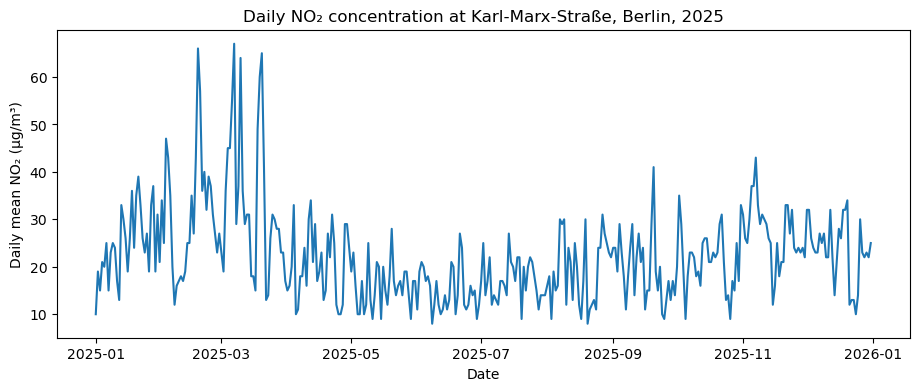

In [7]:
# Daily NO2 through the year
plt.figure(figsize=(11, 4))
plt.plot(data["date"], data["no2"])
plt.xlabel("Date")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Daily NO₂ concentration at Karl-Marx-Straße, Berlin, 2025")
plt.show()

## MODELING

Temperature vs NO2

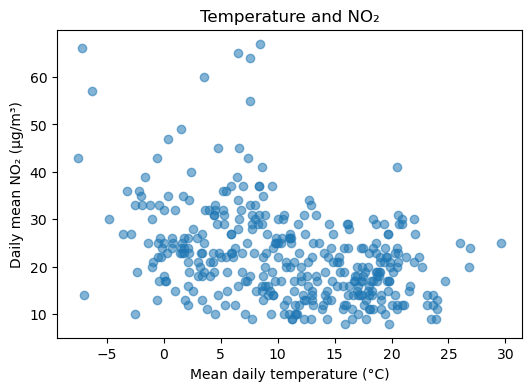

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(data["temp_mean"], data["no2"], alpha=0.55)
plt.xlabel("Mean daily temperature (°C)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Temperature and NO₂")
plt.show()

Wind vs NO2

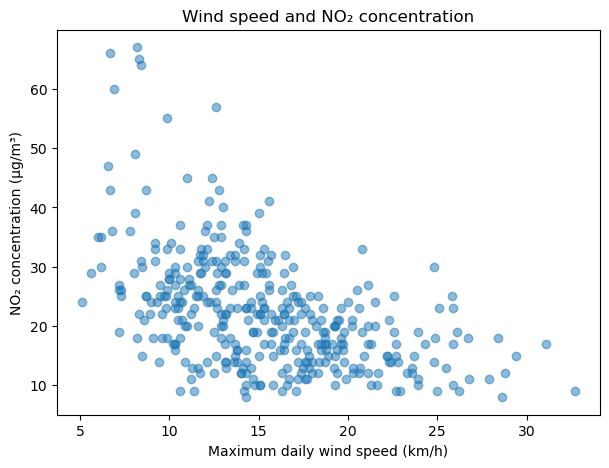

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(data["wind_max"], data["no2"], alpha=0.55)
plt.xlabel("Maximum daily wind speed (km/h)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Wind speed and NO₂")
plt.show()

Precipitation vs NO2

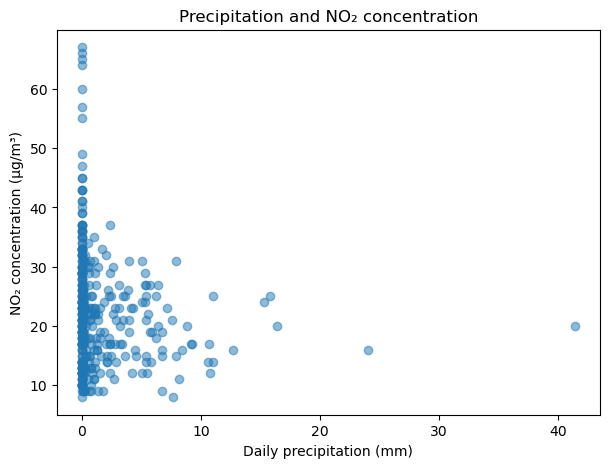

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(data["precip"], data["no2"], alpha=0.55)
plt.xlabel("Daily precipitation (mm)")
plt.ylabel("Daily mean NO₂ (µg/m³)")
plt.title("Precipitation and NO₂")
plt.show()

In [ ]:
# Simple correlations are descriptive only; they are not causal effects.
corr = data[["no2", "temp_mean", "precip", "wind_max"]].corr()
display(corr.round(3))

# Monthly means help show the seasonal structure
monthly = data.groupby(data["date"].dt.month).agg(
    mean_no2=("no2", "mean"),
    mean_temp=("temp_mean", "mean"),
    mean_wind=("wind_max", "mean")
)
display(monthly.round(2))

# Inspect the largest NO2 values instead of deleting them automatically
display(data.nlargest(10, "no2"))

,no2,temp_mean,precip,wind_max
no2,1.000000,-0.378677,-0.129438,-0.499460
temp_mean,-0.378677,1.000000,0.121876,0.137959
precip,-0.129438,0.121876,1.000000,0.248744
wind_max,-0.499460,0.137959,0.248744,1.000000


## Exploratory Data Analysis interpretation

Based on the plots I can see that temperature and wind both have negative simple associations with NO₂. Wind has the stronger correlation, while precipitation is much weaker. I also see several unusually high NO₂ days in late winter and early spring.

This motivate me to create the following models:
1. a simple temperature-only baseline
2. a multiple regression adding wind, because wind is physically connected to pollutant dispersion and has a clear empirical association in the data
3. a quadratic temperature model with wind (temperature + temperature² + wind), to test whether extra nonlinear complexity improves prediction

I will not add precipitation to the main models just because it is available. Its simple association is weak, and adding predictors without a clear reason can make interpretation harder.


## Train-Test Split and Standardization
### Random 80/20 test split

In [ ]:
train, test = train_test_split(
    data,
    test_size=0.20,
    random_state=RANDOM_SEED
)

train = train.copy()
test = test.copy()

print("Training observations:", len(train))
print("Test observations:", len(test))


Training observations: 292
Test observations: 73


Computing predictor means and standar deviations only from the training data (so information doesnt leak into the model)

In [14]:
scaling = {}

for col in ["temp_mean", "wind_max", "precip"]:
    mean = train[col].mean()
    sd = train[col].std()
    scaling[col] = (mean, sd)
    train[col + "_std"] = (train[col] - mean) / sd
    test[col + "_std"] = (test[col] - mean) / sd

train["temp_std2"] = train["temp_mean_std"] ** 2
test["temp_std2"] = test["temp_mean_std"] ** 2

display(pd.DataFrame(scaling, index=["training mean", "training sd"]).T)

,training mean,training sd
temp_mean,11.245890,7.472365
wind_max,15.590411,5.097871
precip,1.513014,3.451117


## Model 1: Temperature Only
y_i \sim \text{Normal}(\mu_i, \sigma), \qquad
\mu_i = \alpha + \beta_T T_i 
where \(T_i\) is standardized temperature.

In [ ]:
with pm.Model() as model_1:
    #priors
    a = pm.Normal("a", mu=train["no2"].mean(), sigma=20)
    b_temp = pm.Normal("b_temp", mu=0, sigma=10)
    sigma = pm.Uniform("sigma", lower=0, upper=50)

    #data
    x_temp = pm.Data("x_temp", train["temp_mean_std"].values)
    y = pm.Data("y", train["no2"].values)

    #regression mean
    mu = pm.Deterministic("mu", a + b_temp * x_temp)
    #likelihood
    pm.Normal("likelihood", mu=mu, sigma=sigma, observed=y)

    prior_1 = pm.sample_prior_predictive(samples=500, random_seed=42)
    idata_1 = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42
    )

az.summary(idata_1, var_names=["a", "b_temp", "sigma"], round_to=2)

Sampling: [a, b_temp, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a, b_temp, sigma]


c:\Users\karla\OneDrive\Documents\CS156_assignment1\.conda\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [ ]:
#check model 1 sampling:
az.summary(
    idata_1,
    var_names=["alpha", "beta_temp", "sigma"],
    round_to=2
)

KeyError: 'var names: "[\'alpha\' \'beta_temp\'] are not present" in dataset'

In [ ]:
az.plot_rank(
    idata_1,
    var_names=["alpha", "beta_temp", "sigma"]
)

plt.show()

## Model 2: temperature + wind

In [ ]:
with pm.Model() as model_2:
    #priors
    a = pm.Normal("a", mu=train["no2"].mean(), sigma=20)
    b_temp = pm.Normal("b_temp", mu=0, sigma=10)
    b_wind = pm.Normal("b_wind", mu=0, sigma=10)
    sigma = pm.Uniform("sigma", lower=0, upper=50)

    x_temp = pm.Data("x_temp", train["temp_mean_std"].values)
    x_wind = pm.Data("x_wind", train["wind_max_std"].values)
    y = pm.Data("y", train["no2"].values)

    mu = pm.Deterministic(
        "mu",
        a + b_temp * x_temp + b_wind * x_wind
    )
    pm.Normal("likelihood", mu=mu, sigma=sigma, observed=y)

    prior_2 = pm.sample_prior_predictive(samples=500, random_seed=RANDOM_SEED)
    idata_2 = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42
    )

az.summary(idata_2, var_names=["a", "b_temp", "b_wind", "sigma"], round_to=2)


Sampling: [a, b_temp, b_wind, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a, b_temp, b_wind, sigma]


c:\Users\karla\OneDrive\Documents\CS156_assignment1\.conda\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1683 seconds.


,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,21.95,0.45,21.26,22.70,0.00,0.0,8345.64,5326.73,1.0
b_temp,-3.25,0.45,-3.95,-2.53,0.01,0.0,7562.72,5826.49,1.0
b_wind,-4.18,0.47,-4.92,-3.43,0.01,0.0,7445.14,6010.48,1.0
sigma,7.72,0.32,7.22,8.24,0.00,0.0,8189.73,5949.74,1.0


In [ ]:
#check model 2 sampling
az.summary(
    idata_2,
    var_names=["alpha", "beta_temp", "beta_wind", "sigma"],
    round_to=2
)

In [ ]:
az.plot_rank(idata_2, var_names=["alpha", "beta_temp", "beta_wind", "sigma"])

plt.show()

## Model 3: quadratic temperature + wind

In [ ]:
with pm.Model() as model_3:
    a = pm.Normal("a", mu=train["no2"].mean(), sigma=20)
    b_temp = pm.Normal("b_temp", mu=0, sigma=10)
    b_temp2 = pm.Normal("b_temp2", mu=0, sigma=10)
    b_wind = pm.Normal("b_wind", mu=0, sigma=10)
    sigma = pm.Uniform("sigma", lower=0, upper=50)

    x_temp = pm.Data("x_temp", train["temp_mean_std"].values)
    x_temp2 = pm.Data("x_temp2", train["temp_std2"].values)
    x_wind = pm.Data("x_wind", train["wind_max_std"].values)
    y = pm.Data("y", train["no2"].values)

    mu = pm.Deterministic(
        "mu",
        a + b_temp * x_temp + b_temp2 * x_temp2 + b_wind * x_wind
    )
    pm.Normal("likelihood", mu=mu, sigma=sigma, observed=y)

    prior_3 = pm.sample_prior_predictive(samples=500, random_seed=RANDOM_SEED)
    idata_3 = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42
    )

az.summary(
    idata_3,
    var_names=["a", "b_temp", "b_temp2", "b_wind", "sigma"],
    round_to=2
)

Sampling: [a, b_temp, b_temp2, b_wind, likelihood, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a, b_temp, b_temp2, b_wind, sigma]


c:\Users\karla\OneDrive\Documents\CS156_assignment1\.conda\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

ValueError: Not enough samples to build a trace.

In [ ]:
az.summary(
    idata_3,
    var_names=[
        "alpha",
        "beta_temp",
        "beta_temp2",
        "beta_wind",
        "sigma"
    ],
    round_to=2
)

In [ ]:
az.plot_rank(
    idata_3,
    var_names=[
        "alpha",
        "beta_temp",
        "beta_temp2",
        "beta_wind",
        "sigma"
    ]
)

plt.show()

Plot posterior distributions

In [ ]:
az.plot_posterior(
    trace_2,
    var_names=["beta_temp", "beta_wind"],
    hdi_prob=0.89
)

plt.show()

In [ ]:
az.plot_posterior(
    trace_3,
    var_names=[
        "beta_temp",
        "beta_temp2",
        "beta_wind"
    ],
    hdi_prob=0.89
)

plt.show()

Posterior predictive checks

In [ ]:
with model_1:
    ppc_1 = pm.sample_posterior_predictive(
        idata_1,
        random_seed=42
    )

In [ ]:
with model_2:
    ppc_2 = pm.sample_posterior_predictive(
        idata_2,
        random_seed=42
    )

In [ ]:
with model_3:
    ppc_3 = pm.sample_posterior_predictive(
        idata_3,
        random_seed=42
    )

In [ ]:
az.plot_ppc(
    ppc_2,
    num_pp_samples=100
)

plt.show()

In [ ]:
with model_1:

    pm.set_data({
        "temp": test["temp_std"].values,
        "no2_obs": test["no2"].values
    })

    pred_1 = pm.sample_posterior_predictive(
        trace_1,
        var_names=["no2"],
        predictions=True,
        random_seed=42
    )

In [ ]:
pred_mean_1 = (
    pred_1.predictions["no2"]
    .mean(dim=("chain", "draw"))
    .values
)

Model 2 predictions

In [ ]:
with model_2:

    pm.set_data({
        "temp": test["temp_std"].values,
        "wind": test["wind_std"].values,
        "no2_obs": test["no2"].values
    })

    pred_2 = pm.sample_posterior_predictive(
        trace_2,
        var_names=["no2"],
        predictions=True,
        random_seed=42
    )

In [ ]:
pred_mean_2 = (
    pred_2.predictions["no2"]
    .mean(dim=("chain", "draw"))
    .values
)

Model 3 Predictions

In [ ]:
with model_3:

    pm.set_data({
        "temp": test["temp_std"].values,
        "temp2": test["temp_std2"].values,
        "wind": test["wind_std"].values,
        "no2_obs": test["no2"].values
    })

    pred_3 = pm.sample_posterior_predictive(
        trace_3,
        var_names=["no2"],
        predictions=True,
        random_seed=42
    )

In [ ]:
pred_mean_3 = (
    pred_3.predictions["no2"]
    .mean(dim=("chain", "draw"))
    .values
)

## Model Comparison

I chose RMSE

In [ ]:
rmse_1 = np.sqrt(
    mean_squared_error(
        test["no2"],
        pred_mean_1
    )
)

rmse_2 = np.sqrt(
    mean_squared_error(
        test["no2"],
        pred_mean_2
    )
)

rmse_3 = np.sqrt(
    mean_squared_error(
        test["no2"],
        pred_mean_3
    )
)

print("Model 1 RMSE:", rmse_1)
print("Model 2 RMSE:", rmse_2)
print("Model 3 RMSE:", rmse_3)

MAE calculations

In [ ]:
mae_1 = mean_absolute_error(
    test["no2"],
    pred_mean_1
)

mae_2 = mean_absolute_error(
    test["no2"],
    pred_mean_2
)

mae_3 = mean_absolute_error(
    test["no2"],
    pred_mean_3
)

print("Model 1 MAE:", mae_1)
print("Model 2 MAE:", mae_2)
print("Model 3 MAE:", mae_3)

Model comparison table

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Temperature only",
        "Temperature + wind",
        "Quadratic temperature + wind"
    ],

    "RMSE": [
        rmse_1,
        rmse_2,
        rmse_3
    ],

    "MAE": [
        mae_1,
        mae_2,
        mae_3
    ]
})

results

Predicted vs observed plot

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    test["no2"],
    pred_mean_2,
    alpha=0.7
)

minimum = min(
    test["no2"].min(),
    pred_mean_2.min()
)

maximum = max(
    test["no2"].max(),
    pred_mean_2.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Observed NO₂ (µg/m³)")
plt.ylabel("Predicted NO₂ (µg/m³)")
plt.title("Observed vs predicted NO₂ — Model 2")

plt.show()

Add posterior predictive uncertainty to test predictions

In [ ]:
pred_samples_2 = pred_2.predictions["no2"].stack(
    sample=("chain", "draw")
).values

In [ ]:
#(number of test observations, number of posterior samples)
pred_samples_2.shape

In [ ]:
lower_2 = np.quantile(
    pred_samples_2,
    0.055,
    axis=1
)

upper_2 = np.quantile(
    pred_samples_2,
    0.945,
    axis=1
)

In [ ]:
test_results = test.copy()

test_results["pred_mean"] = pred_mean_2
test_results["pred_lower"] = lower_2
test_results["pred_upper"] = upper_2

In [ ]:
test_results = test_results.sort_values("date")

In [ ]:
plt.figure(figsize=(12, 5))

plt.scatter(
    test_results["date"],
    test_results["no2"],
    label="Observed"
)

plt.plot(
    test_results["date"],
    test_results["pred_mean"],
    label="Posterior predictive mean"
)

plt.fill_between(
    test_results["date"],
    test_results["pred_lower"],
    test_results["pred_upper"],
    alpha=0.25,
    label="89% predictive interval"
)

plt.xlabel("Date")
plt.ylabel("NO₂ (µg/m³)")
plt.title("Model predictions on held-out test data")

plt.legend()
plt.show()